# Score and compare the BLIP-2 query experiment

Run after `query_ablation.ipynb` with **Python (blip2 AMD)**. This notebook uses CPU
scoring and reuses the saved predictions. Set the stage and optionally an exact
experiment directory below. It selects the most recently completed experiment for
that stage when no directory is supplied, and prints the chosen path.

Scoring uses the official GT-Vision-Lab VQA evaluator at a pinned revision. Its two
Python 2 print statements are translated to Python 3. Its normalization and scoring
logic are preserved, including the average over the ten held-out annotators.
The first scoring run downloads the small evaluator source and verifies its SHA256.

Confidence intervals use paired image-cluster bootstrap resampling, keeping all
questions about a sampled image together. Group confidence intervals condition on
the five chosen query subsets. Query-selection standard deviations are reported
separately. Smoke results validate the workflow and are too small for conclusions.


In [1]:
from pathlib import Path
import copy
import hashlib
import json
import os
import types
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from filelock import FileLock
from IPython.display import display

STAGE = os.environ.get("BLIP2_STAGE", "main")
EXPERIMENT_DIR = None  # Or Path(r"D:\STATS 425 BLIP2\results\query_ablation\main-...")
BOOTSTRAP_REPLICATES = 2000
BOOTSTRAP_SEED = 425

cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "scripts" else cwd
RESULTS_ROOT = PROJECT_ROOT / "results" / "query_ablation"
if EXPERIMENT_DIR is None:
    candidates = sorted(RESULTS_ROOT.glob(f"{STAGE}-*/complete.json"), key=lambda path: path.stat().st_mtime)
    if not candidates:
        raise FileNotFoundError(f"No completed {STAGE} experiment. Run query_ablation.ipynb first.")
    EXPERIMENT_DIR = candidates[-1].parent
EXPERIMENT_DIR = Path(EXPERIMENT_DIR).resolve()
manifest = json.loads((EXPERIMENT_DIR / "manifest.json").read_text(encoding="utf-8"))
experiment = manifest["experiment"]
complete = json.loads((EXPERIMENT_DIR / "complete.json").read_text(encoding="utf-8"))
expected_signature = hashlib.sha256(json.dumps(experiment, sort_keys=True).encode()).hexdigest()
if complete["signature"] != manifest["signature"] or expected_signature != manifest["signature"]:
    raise ValueError("Experiment manifest or completion signature differs.")
print("Scoring:", EXPERIMENT_DIR)
print("Hardware:", experiment["gpu_name"], "| model:", experiment["model_id"])
print("Questions per condition:", len(experiment["question_ids"]))


Scoring: D:\STATS 425 BLIP2\results\query_ablation\main-825216e39c820d63
Hardware: AMD Radeon RX 9070 | model: Salesforce/blip2-flan-t5-xl
Questions per condition: 2000


In [2]:
EVALUATOR_REVISION = "a013f0043c1e2cdc995922dfe257f7149aa9af06"
EVALUATOR_SHA256 = "f08edfcad5be0112500993e245c706b6cb928eadebe203f89f838e5e0d04bec8"
EVALUATOR_URL = (
    f"https://raw.githubusercontent.com/GT-Vision-Lab/VQA/{EVALUATOR_REVISION}/"
    "PythonEvaluationTools/vqaEvaluation/vqaEval.py"
)
cache = RESULTS_ROOT / "evaluator"
cache.mkdir(parents=True, exist_ok=True)
source_path = cache / f"vqaEval-{EVALUATOR_REVISION}.txt"
with FileLock(str(cache / "download.lock"), timeout=60):
    if source_path.exists():
        source_bytes = source_path.read_bytes()
    else:
        with urllib.request.urlopen(EVALUATOR_URL, timeout=60) as response:
            source_bytes = response.read()
    if hashlib.sha256(source_bytes).hexdigest() != EVALUATOR_SHA256:
        raise ValueError("Official evaluator source failed its SHA256 check.")
    source_path.write_bytes(source_bytes)

source = source_bytes.decode("utf-8")
source = source.replace('print "computing accuracy"', 'print("computing accuracy")')
source = source.replace('print "Done computing accuracy"', 'print("Done computing accuracy")')
official_evaluator = types.ModuleType("official_vqa_evaluator")
exec(compile(source, str(source_path), "exec"), official_evaluator.__dict__)
VQAEval = official_evaluator.VQAEval
print("Official VQA evaluator verified:", EVALUATOR_REVISION)


Official VQA evaluator verified: a013f0043c1e2cdc995922dfe257f7149aa9af06


D:\STATS 425 BLIP2\results\query_ablation\evaluator\vqaEval-a013f0043c1e2cdc995922dfe257f7149aa9af06.txt:62: SyntaxWarning: invalid escape sequence '\d'
  self.periodStrip  = re.compile("(?!<=\d)(\.)(?!\d)")
D:\STATS 425 BLIP2\results\query_ablation\evaluator\vqaEval-a013f0043c1e2cdc995922dfe257f7149aa9af06.txt:63: SyntaxWarning: invalid escape sequence '\d'
  self.commaStrip   = re.compile("(\d)(\,)(\d)")


In [3]:
annotations_path = PROJECT_ROOT / "data" / "validation_dataset" / "v2_mscoco_val2014_annotations_subset.json"
if hashlib.sha256(annotations_path.read_bytes()).hexdigest() != experiment["annotation_file_sha256"]:
    raise ValueError("Annotations changed since predictions were generated.")
annotations = json.loads(annotations_path.read_text(encoding="utf-8"))["annotations"]
annotation_by_id = {int(annotation["question_id"]): annotation for annotation in annotations}
question_ids = experiment["question_ids"]


def score_predictions(predictions):
    ids = [item["question_id"] for item in predictions]
    if ids != question_ids:
        raise ValueError("Prediction IDs must match the exact ordered evaluation set.")
    ground_truth = types.SimpleNamespace(
        qa={qid: copy.deepcopy(annotation_by_id[qid]) for qid in question_ids},
        getQuesIds=lambda: question_ids,
    )
    answers = types.SimpleNamespace(qa={item["question_id"]: item for item in predictions})
    evaluator = VQAEval(ground_truth, answers, n=6)
    evaluator.evaluate(quesIds=question_ids)
    return evaluator


summaries = []
scored_rows = []
answer_type_rows = []
# Read only completed records while holding the same lock used by generation.
with FileLock(str(EXPERIMENT_DIR / "experiment.lock"), timeout=0):
    for condition in experiment["conditions"]:
        directory = EXPERIMENT_DIR / condition["name"]
        status = json.loads((directory / "status.json").read_text(encoding="utf-8"))
        if status["state"] != "complete" or status["completed"] != len(question_ids):
            raise ValueError(f"Incomplete condition {condition['name']}.")
        records = [json.loads(line) for line in (directory / "records.jsonl").read_text(encoding="utf-8").splitlines()]
        if [row["question_id"] for row in records] != question_ids:
            raise ValueError("Missing, duplicate, or unexpected saved question IDs.")
        for row in records:
            if row["k"] != condition["k"] or row["query_seed"] != condition["seed"]:
                raise ValueError("Prediction condition does not match the manifest.")
            if row["image_id"] != int(annotation_by_id[row["question_id"]]["image_id"]):
                raise ValueError("Prediction image ID differs from its annotation.")
        predictions = json.loads((directory / "predictions.json").read_text(encoding="utf-8"))
        if predictions != [{"question_id": row["question_id"], "answer": row["answer"]} for row in records]:
            raise ValueError("Exported predictions differ from the resumable records.")
        evaluator = score_predictions(predictions)
        frame = pd.DataFrame(records)
        summaries.append({
            "condition": condition["name"], "k": condition["k"], "seed": condition["seed"],
            "kind": condition["kind"], "questions": len(records),
            "vqa_accuracy_pct": evaluator.accuracy["overall"],
            "mean_latency_seconds": frame.generation_seconds.mean(),
            "median_latency_seconds": frame.generation_seconds.median(),
            "p95_latency_seconds": frame.generation_seconds.quantile(0.95),
            "throughput_questions_per_second": len(frame) / frame.generation_seconds.sum(),
            "peak_allocated_gib": frame.peak_allocated_bytes.max() / 2**30,
            "peak_reserved_gib": frame.peak_reserved_bytes.max() / 2**30,
            "mean_generated_tokens": frame.generated_token_count.mean(),
        })
        for row in records:
            row = dict(row, condition=condition["name"], kind=condition["kind"],
                       vqa_score_pct=evaluator.evalQA[row["question_id"]])
            scored_rows.append(row)
        for answer_type, accuracy in evaluator.accuracy["perAnswerType"].items():
            answer_type_rows.append({"condition": condition["name"], "k": condition["k"],
                                     "seed": condition["seed"], "answer_type": answer_type,
                                     "vqa_accuracy_pct": accuracy})

summary = pd.DataFrame(summaries).sort_values(["k", "seed"])
per_question = pd.DataFrame(scored_rows)
display(summary)


computing accuracy
Finshed Percent: [###################-] 95% Done computing accuracy
computing accuracy
Finshed Percent: [###################-] 95% Done computing accuracy
computing accuracy
Finshed Percent: [###################-] 95% Done computing accuracy
computing accuracy
Finshed Percent: [###################-] 95% Done computing accuracy
computing accuracy
Finshed Percent: [###################-] 95% Done computing accuracy
computing accuracy
Finshed Percent: [###################-] 95% Done computing accuracy
computing accuracy
Finshed Percent: [###################-] 95% Done computing accuracy
computing accuracy
Finshed Percent: [###################-] 95% Done computing accuracy
computing accuracy
Finshed Percent: [###################-] 95% Done computing accuracy
computing accuracy
Finshed Percent: [###################-] 95% Done computing accuracy
computing accuracy
Finshed Percent: [###################-] 95% Done computing accuracy
computing accuracy
Finshed Percent: [######

,condition,k,seed,kind,questions,vqa_accuracy_pct,mean_latency_seconds,median_latency_seconds,p95_latency_seconds,throughput_questions_per_second,peak_allocated_gib,peak_reserved_gib,mean_generated_tokens
0,k008-seed000,8,0.0,pruning,2000,50.745,0.176421,0.161477,0.285743,5.668274,7.475838,7.535156,2.3135
12,k008-seed001,8,1.0,pruning,2000,52.835,0.170616,0.159174,0.268833,5.861117,7.476754,7.535156,2.3150
2,k008-seed002,8,2.0,pruning,2000,54.110,0.166854,0.157861,0.250550,5.993262,7.476754,7.535156,2.2750
7,k008-seed003,8,3.0,pruning,2000,54.300,0.152742,0.146177,0.227431,6.546979,7.476754,7.535156,2.2750
6,k008-seed004,8,4.0,pruning,2000,54.735,0.172658,0.168766,0.262220,5.791797,7.478585,7.535156,2.3135
11,k016-seed000,16,0.0,pruning,2000,56.765,0.193684,0.186371,0.303601,5.163055,7.486299,7.539062,2.3470
5,k016-seed001,16,1.0,pruning,2000,50.610,0.160367,0.156646,0.242550,6.235696,7.484468,7.537109,2.3140
3,k016-seed002,16,2.0,pruning,2000,57.390,0.164849,0.157298,0.255202,6.066153,7.484468,7.535156,2.3030
10,k016-seed003,16,3.0,pruning,2000,58.110,0.154882,0.145658,0.238540,6.456537,7.484468,7.537109,2.3170
1,k016-seed004,16,4.0,pruning,2000,59.355,0.189768,0.183882,0.299649,5.269594,7.485383,7.537109,2.3310


In [4]:
def paired_image_bootstrap(delta, image_ids, replicates=BOOTSTRAP_REPLICATES):
    """Question-weighted mean difference, resampling distinct images together."""
    unique_images, codes = np.unique(np.asarray(image_ids), return_inverse=True)
    sums = np.bincount(codes, weights=np.asarray(delta, dtype=float))
    counts = np.bincount(codes)
    generator = np.random.default_rng(BOOTSTRAP_SEED)
    samples = np.empty(replicates)
    for index in range(replicates):
        drawn = generator.integers(0, len(unique_images), size=len(unique_images))
        samples[index] = sums[drawn].sum() / counts[drawn].sum()
    return np.quantile(samples, [0.025, 0.975])


scores = per_question.pivot(index="question_id", columns="condition", values="vqa_score_pct").reindex(question_ids)
if scores.isna().any().any():
    raise ValueError("All comparisons require the same complete question set.")
baseline = scores["k032"]
image_ids = [int(annotation_by_id[qid]["image_id"]) for qid in question_ids]
comparisons = []
for condition in experiment["conditions"]:
    delta = scores[condition["name"]] - baseline
    lower, upper = paired_image_bootstrap(delta, image_ids)
    comparisons.append({
        "condition": condition["name"], "k": condition["k"], "seed": condition["seed"],
        "delta_accuracy_pp": delta.mean(), "ci_lower_pp": lower, "ci_upper_pp": upper,
    })
comparisons = pd.DataFrame(comparisons).sort_values(["k", "seed"])

group_rows = []
for k, runs in summary.groupby("k", sort=True):
    names = runs.condition.tolist()
    mean_scores = scores[names].mean(axis=1)
    delta = mean_scores - baseline
    lower, upper = paired_image_bootstrap(delta, image_ids)
    group_rows.append({
        "k": k, "kind": runs.kind.iloc[0], "query_subsets": len(runs),
        "mean_accuracy_pct": mean_scores.mean(),
        "query_subset_accuracy_sd_pp": runs.vqa_accuracy_pct.std(ddof=1) if len(runs) > 1 else np.nan,
        "delta_vs_k32_pp": delta.mean(), "paired_ci_lower_pp": lower, "paired_ci_upper_pp": upper,
        "mean_median_latency_seconds": runs.median_latency_seconds.mean(),
        "mean_throughput_questions_per_second": runs.throughput_questions_per_second.mean(),
        "max_peak_allocated_gib": runs.peak_allocated_gib.max(),
        "mean_generated_tokens": runs.mean_generated_tokens.mean(),
    })
group_summary = pd.DataFrame(group_rows)
display(group_summary)
print("Intervals are paired image-bootstrap intervals, conditional on the selected query subsets.")
print("Query-subset standard deviations describe a separate source of variability.")
if experiment["stage"] == "smoke":
    print("Smoke results check functionality. Use the main stage for the project analysis.")


,k,kind,query_subsets,mean_accuracy_pct,query_subset_accuracy_sd_pp,delta_vs_k32_pp,paired_ci_lower_pp,paired_ci_upper_pp,mean_median_latency_seconds,mean_throughput_questions_per_second,max_peak_allocated_gib,mean_generated_tokens
0,8,pruning,5,53.345,1.616280,-6.110,-7.457684,-4.720388,0.158691,5.972286,7.478585,2.2984
1,16,pruning,5,56.446,3.401579,-3.009,-4.075854,-1.961012,0.165971,5.838207,7.486299,2.3224
2,32,baseline,1,59.455,NaN,0.000,0.000000,0.000000,0.167911,5.823840,7.503256,2.3650
3,64,repeated-query control,1,58.670,NaN,-0.785,-1.580224,-0.004987,0.174000,5.604355,7.531744,2.3640
4,128,repeated-query control,1,57.745,NaN,-1.710,-2.640904,-0.720686,0.165282,5.957348,7.594696,2.3595


Intervals are paired image-bootstrap intervals, conditional on the selected query subsets.
Query-subset standard deviations describe a separate source of variability.


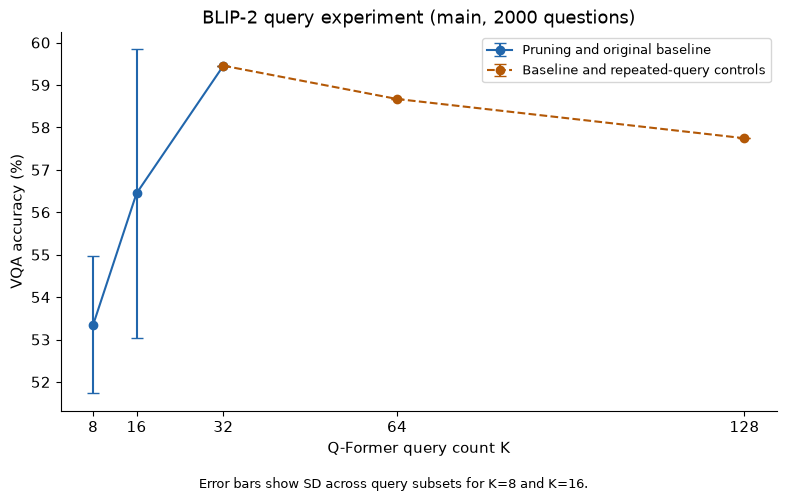

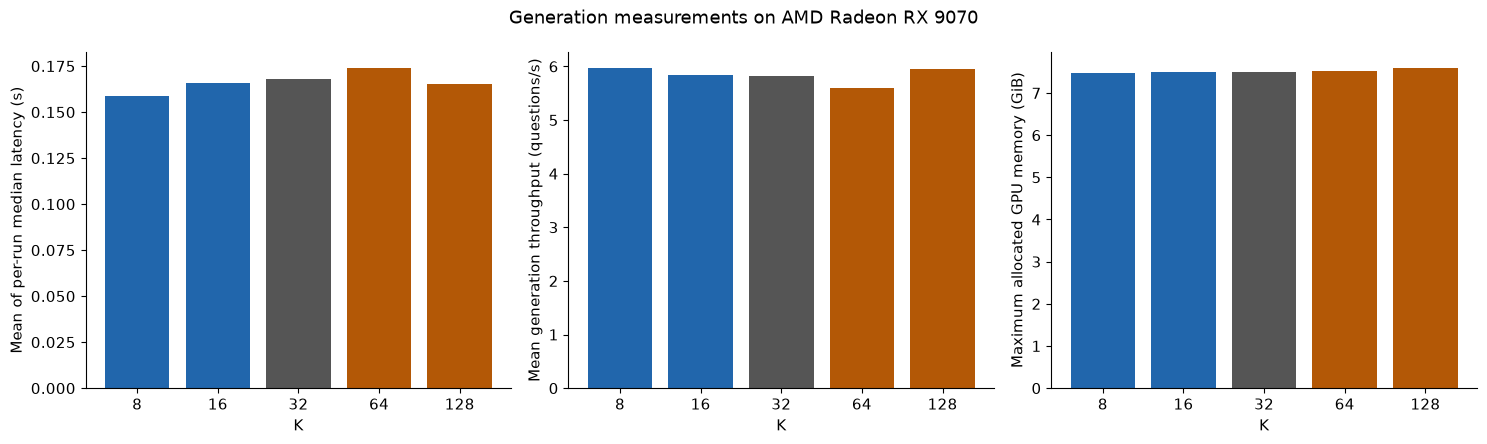

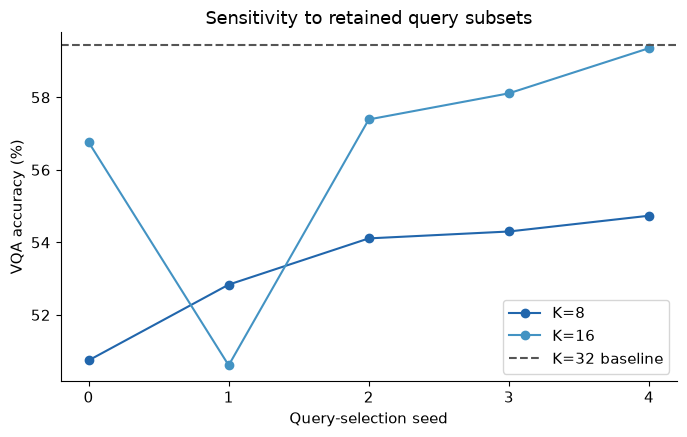

Saved tables and figures to D:\STATS 425 BLIP2\results\query_ablation\main-825216e39c820d63\analysis


In [5]:
report_dir = EXPERIMENT_DIR / "analysis"
report_dir.mkdir(exist_ok=True)
summary.to_csv(report_dir / "run_summary.csv", index=False)
per_question.to_csv(report_dir / "per_question_scores.csv", index=False)
comparisons.to_csv(report_dir / "paired_comparisons.csv", index=False)
group_summary.to_csv(report_dir / "group_summary.csv", index=False)
pd.DataFrame(answer_type_rows).to_csv(report_dir / "accuracy_by_answer_type.csv", index=False)
(report_dir / "scoring_protocol.json").write_text(json.dumps({
    "experiment_signature": manifest["signature"], "evaluator_revision": EVALUATOR_REVISION,
    "evaluator_sha256": EVALUATOR_SHA256, "bootstrap_replicates": BOOTSTRAP_REPLICATES,
    "bootstrap_seed": BOOTSTRAP_SEED, "resampling_unit": "image",
    "group_interval_conditions_on": "the fixed query subsets", "score_units": "percent",
}, indent=2) + "\n", encoding="utf-8")

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(8, 5))
for name, ks, color, style in [
    ("Pruning and original baseline", [8, 16, 32], "#2166ac", "-"),
    ("Baseline and repeated-query controls", [32, 64, 128], "#b35806", "--"),
]:
    rows = group_summary[group_summary.k.isin(ks)]
    ax.errorbar(rows.k, rows.mean_accuracy_pct,
                yerr=rows.query_subset_accuracy_sd_pp.fillna(0),
                marker="o", linestyle=style, color=color, capsize=4, label=name)
ax.set(xlabel="Q-Former query count K", ylabel="VQA accuracy (%)",
       title=f"BLIP-2 query experiment ({experiment['stage']}, {len(question_ids)} questions)",
       xticks=[8, 16, 32, 64, 128])
ax.legend(fontsize=9)
fig.text(0.5, 0.01, "Error bars show SD across query subsets for K=8 and K=16.", ha="center", fontsize=9)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(report_dir / "accuracy_vs_k.png", dpi=200)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
colors = ["#2166ac", "#2166ac", "#555555", "#b35806", "#b35806"]
for ax, column, label in [
    (axes[0], "mean_median_latency_seconds", "Mean of per-run median latency (s)"),
    (axes[1], "mean_throughput_questions_per_second", "Mean generation throughput (questions/s)"),
    (axes[2], "max_peak_allocated_gib", "Maximum allocated GPU memory (GiB)"),
]:
    ax.bar(group_summary.k.astype(str), group_summary[column], color=colors)
    ax.set(xlabel="K", ylabel=label)
fig.suptitle(f"Generation measurements on {experiment['gpu_name']}")
fig.tight_layout()
fig.savefig(report_dir / "efficiency_vs_k.png", dpi=200)
plt.show()

fig, ax = plt.subplots(figsize=(7, 4.5))
for k, color in [(8, "#2166ac"), (16, "#4393c3")]:
    rows = summary[summary.k == k]
    ax.plot(rows.seed, rows.vqa_accuracy_pct, marker="o", color=color, label=f"K={k}")
ax.axhline(float(summary.loc[summary.k == 32, "vqa_accuracy_pct"].iloc[0]),
           color="#555555", linestyle="--", label="K=32 baseline")
ax.set(xlabel="Query-selection seed", ylabel="VQA accuracy (%)",
       title="Sensitivity to retained query subsets", xticks=experiment["query_seeds"])
ax.legend()
fig.tight_layout()
fig.savefig(report_dir / "query_selection_variability.png", dpi=200)
plt.show()
print("Saved tables and figures to", report_dir)
